# Explicabilidade e calibração do modelo campeão

O modelo campeão do notebook 3 é o **LightGBM (passo 6)**. Este notebook:

1. reconstrói o modelo com o mesmo split, variáveis e hiperparâmetros e **reproduz as métricas de escolha** (PR AUC, ROC AUC, KS, recall nos thresholds fixos e custo operacional);
2. faz um breve ensaio de **explicabilidade**: importância nativa (gain), *permutation importance* (sobre PR AUC e sobre custo), **SHAP** (global, dependência, interações e casos individuais) e PDP/ICE;
3. avalia a **calibração** do score (curva de confiabilidade, Brier, ECE) e testa recalibrações ajustadas na validação.

O modelo é retreinado aqui (determinístico, `random_state=42`) em vez de carregado do MLflow, para o notebook não depender do servidor de tracking.

In [1]:
import sys
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss

sys.path.append("../")

from utils.metrics import classification_metrics
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve

warnings.filterwarnings("ignore")

## Dados, split e variáveis

Idênticos ao notebook 3.

In [2]:
df = pd.read_csv("../data/nuvem_fraud_dataset_pos_eda_v2.csv", sep=";", index_col=0)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)

df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(conds, ["warmup", "train", "gap1", "valid", "gap2", "test"], default="unassigned")

target = "is_fraud"
ratio_col = "amount_to_customer_median_ratio_30d"
amount_cutoff = 200
night_hours = [22, 23, 0, 1, 2, 3]

vertical_groups = {
    "vertical_high_risk": ["shopping_net", "grocery_pos", "misc_net"],
    "vertical_medium_risk": ["shopping_pos", "gas_transport", "travel", "misc_pos"],
    "vertical_low_risk": [
        "grocery_net", "entertainment", "personal_care", "kids_pets",
        "food_dining", "health_fitness", "home",
    ],
}
vertical_to_group = {v: g for g, vs in vertical_groups.items() for v in vs}

train = df[df["split"] == "train"].copy()
valid = df[df["split"] == "valid"].copy()
test = df[df["split"] == "test"].copy()
splits = {"train": train, "valid": valid, "test": test}

for data in splits.values():
    data["high_amount"] = data["amount"].gt(amount_cutoff).astype(int)
    data["vertical_group"] = pd.Categorical(
        data["vertical"].map(vertical_to_group), categories=list(vertical_groups)
    )
    data["night"] = data["created_at"].dt.hour.isin(night_hours).astype(int)

lgbm_features = ["high_amount", "vertical_group", "night", "txns_prev_1h", ratio_col]

## Modelo campeão

In [3]:
lgbm_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "min_child_samples": 100,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "random_state": 42,
    "verbose": -1,
}

lgbm = lgb.LGBMClassifier(**lgbm_params).fit(
    train[lgbm_features],
    train[target],
    eval_set=[(valid[lgbm_features], valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
scores = {name: lgbm.predict_proba(data[lgbm_features])[:, 1] for name, data in splits.items()}
print(f"Melhor iteração: {lgbm.best_iteration_}")

Melhor iteração: 101


# 1. Reprodução das métricas de escolha

Mesma função de avaliação do notebook 3; threshold de decisão = menor custo na **validação**. Referência do notebook 3 no teste: PR AUC 0,400, KS 0,824, custo R$ 41.364, bloqueio 0,71%.

In [4]:
pnl_params = {"chargeback_fee": 15.0, "margin": 0.10, "review_cost": 5.0}


def evaluate(y_true, y_score, amount, threshold: float) -> dict[str, float]:
    y = np.asarray(y_true).astype(bool)
    s = np.asarray(y_score, dtype=float)
    pnl = decision_pnl(y, s >= threshold, amount, **pnl_params)
    return {
        **{k: v for k, v in classification_metrics(y, s).items() if k in ("pr_auc", "roc_auc", "ks")},
        "recall_at_0.05": (y & (s >= 0.05)).sum() / max(y.sum(), 1),
        "recall_at_0.1": (y & (s >= 0.1)).sum() / max(y.sum(), 1),
        **{k: pnl[k] for k in ("block_rate", "recall", "precision", "fn_cost", "fp_cost",
                               "total_cost", "savings_vs_approve_all")},
    }


def evaluate_splits(scores: dict[str, np.ndarray], threshold: float) -> pd.DataFrame:
    return pd.DataFrame(
        {name: evaluate(data[target], scores[name], data["amount"], threshold)
         for name, data in splits.items()}
    ).T


curve_valid = threshold_cost_curve(valid[target], scores["valid"], valid["amount"], **pnl_params)
threshold = optimal_threshold(curve_valid)
metrics = evaluate_splits(scores, threshold)
print(f"Threshold de decisão (ótimo na validação): {threshold:.4f}")
metrics

Threshold de decisão (ótimo na validação): 0.1134


,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.547623,0.976283,0.857051,0.703192,0.633305,0.008414,0.629853,0.425408,119240.82,61566.455,180807.275,430508.265
valid,0.451449,0.969117,0.851503,0.679803,0.635468,0.007458,0.635468,0.359331,14011.98,12370.697,26382.677,82170.893
test,0.400001,0.961967,0.824484,0.654971,0.543860,0.007138,0.543860,0.252717,24771.94,16592.537,41364.477,46282.223


In [5]:
reference_test = {"pr_auc": 0.400001, "roc_auc": 0.961967, "ks": 0.824484, "total_cost": 41364.477}
check = pd.DataFrame({"notebook_3": reference_test, "reproduzido": metrics.loc["test", list(reference_test)]})
check["diferença"] = check["reproduzido"] - check["notebook_3"]
check

,notebook_3,reproduzido,diferença
pr_auc,0.400001,0.400001,-3.853892e-07
roc_auc,0.961967,0.961967,2.502784e-07
ks,0.824484,0.824484,3.579258e-07
total_cost,41364.477000,41364.477000,0.000000e+00


### Curva de custo por threshold

O ótimo da validação é aplicado no teste; a curva do teste mostra quanto se perde por não conhecer o ótimo *ex post*.

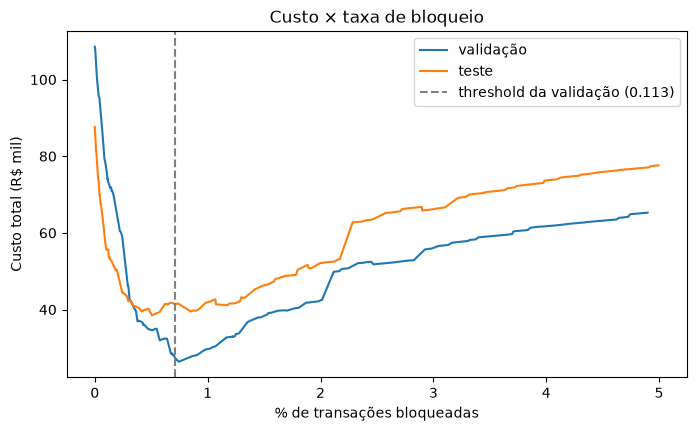

Custo no teste com threshold da validação: R$ 41,364
Custo ótimo ex post no teste:              R$ 38,483 (threshold 0.196)


In [6]:
curve_test = threshold_cost_curve(test[target], scores["test"], test["amount"], **pnl_params)
best_test = curve_test.loc[curve_test["total_cost"].idxmin()]

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, curve in [("validação", curve_valid), ("teste", curve_test)]:
    c = curve[curve["block_rate"] <= 0.05]
    ax.plot(c["block_rate"] * 100, c["total_cost"] / 1e3, label=name)
ax.axvline(metrics.loc["test", "block_rate"] * 100, color="gray", ls="--", label=f"threshold da validação ({threshold:.3f})")
ax.set_xlabel("% de transações bloqueadas")
ax.set_ylabel("Custo total (R$ mil)")
ax.set_title("Custo × taxa de bloqueio")
ax.legend()
plt.show()

print(f"Custo no teste com threshold da validação: R$ {metrics.loc['test', 'total_cost']:,.0f}")
print(f"Custo ótimo ex post no teste:              R$ {best_test.total_cost:,.0f} (threshold {best_test.threshold:.3f})")

# 2. Explicabilidade

## 2.1 Importância nativa (gain) × permutation importance

A importância por *gain* é calculada no treino e favorece variáveis com muitos pontos de corte. A **permutation importance** é calculada no **teste**: embaralha uma variável e mede a perda de desempenho — aqui, em PR AUC e no **custo operacional** com o threshold fixo, que é a métrica de negócio.

In [7]:
X_test, y_test = test[lgbm_features], test[target]


def cost_scorer(estimator, X, y):
    s = estimator.predict_proba(X)[:, 1]
    return -decision_pnl(y, s >= threshold, test.loc[X.index, "amount"], **pnl_params)["total_cost"]


def pr_auc_scorer(estimator, X, y):
    return average_precision_score(y, estimator.predict_proba(X)[:, 1])


perm = {
    name: permutation_importance(lgbm, X_test, y_test, scoring=scorer, n_repeats=10, random_state=42)
    for name, scorer in [("pr_auc", pr_auc_scorer), ("custo_R$", cost_scorer)]
}

gain = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"), index=lgbm_features)
importances = pd.DataFrame({
    "gain_%": gain / gain.sum() * 100,
    "perm_queda_pr_auc": perm["pr_auc"].importances_mean,
    "perm_queda_pr_auc_std": perm["pr_auc"].importances_std,
    "perm_aumento_custo_R$": perm["custo_R$"].importances_mean,
    "perm_aumento_custo_std": perm["custo_R$"].importances_std,
}, index=lgbm_features).sort_values("perm_queda_pr_auc", ascending=False)
importances.round(3)

,gain_%,perm_queda_pr_auc,perm_queda_pr_auc_std,perm_aumento_custo_R$,perm_aumento_custo_std
high_amount,41.887,0.383,0.003,61288.713,2027.387
night,21.963,0.274,0.019,30618.326,3177.134
amount_to_customer_median_ratio_30d,24.142,0.209,0.010,62798.397,3136.137
txns_prev_1h,5.567,0.081,0.022,777.040,709.865
vertical_group,6.441,0.059,0.009,2092.785,1419.586


## 2.2 SHAP

`TreeExplainer` (exato para árvores) sobre o teste. Os valores SHAP estão em **log-odds**: somados ao valor base, reproduzem o logit do score. Para o resumo global usamos todas as fraudes do teste e uma amostra das legítimas (a base é muito desbalanceada; o *beeswarm* com todas as legítimas esconderia as fraudes).

In [8]:
explainer = shap.TreeExplainer(lgbm)

rng = np.random.default_rng(42)
idx_fraud = test.index[test[target] == 1]
idx_legit = rng.choice(test.index[test[target] == 0], size=5000, replace=False)
X_shap = X_test.loc[np.r_[idx_fraud, idx_legit]]

sv = explainer(X_shap)
if sv.values.ndim == 3:  # algumas versões devolvem as duas classes
    sv = sv[:, :, 1]

# Checagem de aditividade: base + soma dos SHAP = logit do score
logit = np.log(lgbm.predict_proba(X_shap)[:, 1] / (1 - lgbm.predict_proba(X_shap)[:, 1]))
print("Erro máximo de aditividade:", np.abs(sv.base_values + sv.values.sum(1) - logit).max())

Erro máximo de aditividade: 1.6431300764452317e-14


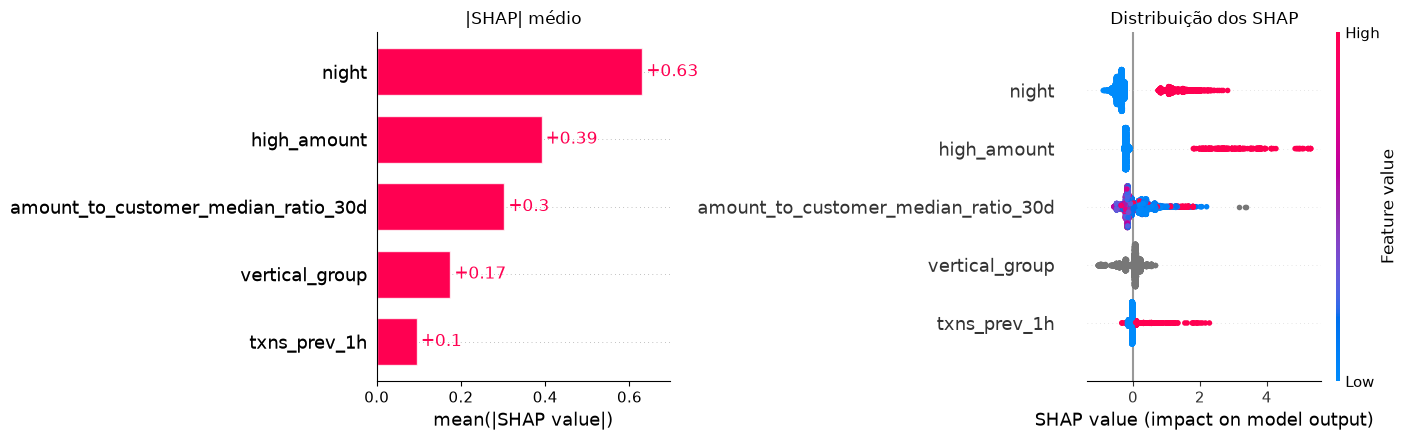

In [9]:
fig = plt.figure(figsize=(14, 4.5))
plt.subplot(1, 2, 1)
shap.plots.bar(sv, show=False, ax=plt.gca())
plt.title("|SHAP| médio")
plt.subplot(1, 2, 2)
shap.plots.beeswarm(sv, show=False, plot_size=None)
plt.title("Distribuição dos SHAP")
plt.tight_layout()
plt.show()

### Dependência

Efeito de cada variável contínua/contagem no logit, colorido pela variável com que mais interage. A razão sobre a mediana de 30d deve mostrar o "degrau" no último decil visto no notebook 3 — exatamente o que a regressão logística não capturava.

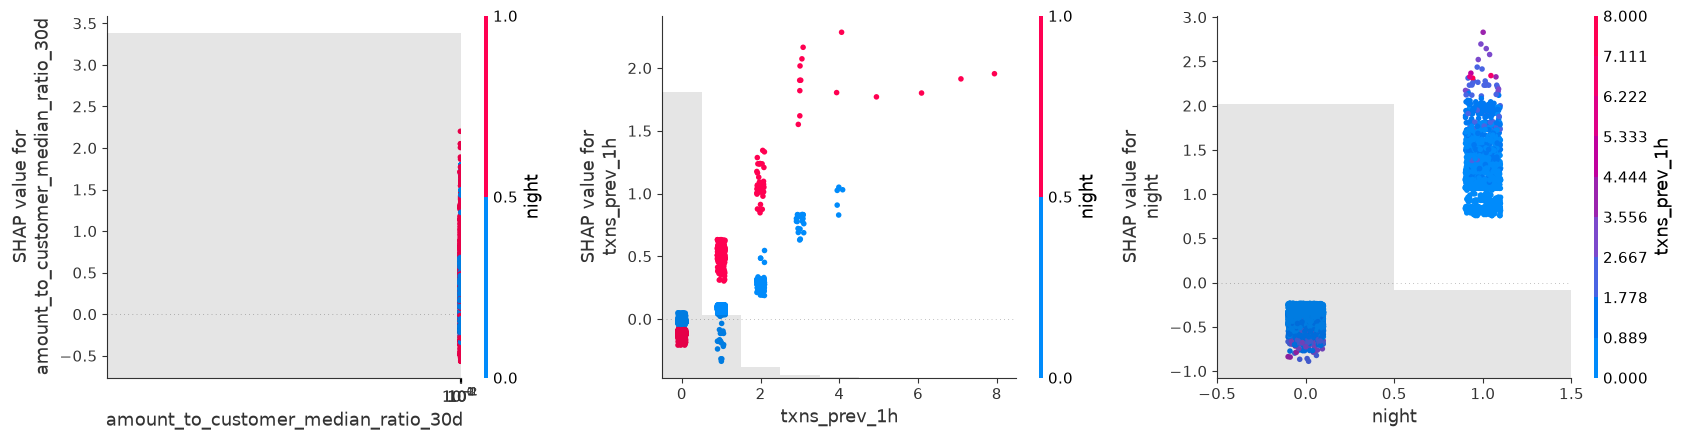

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
X_plot = X_shap.copy()
shap.plots.scatter(sv[:, ratio_col], color=sv, ax=axes[0], show=False)
axes[0].set_xscale("log")
shap.plots.scatter(sv[:, "txns_prev_1h"], color=sv, ax=axes[1], show=False)
shap.plots.scatter(sv[:, "night"], color=sv, ax=axes[2], show=False)
plt.tight_layout()
plt.show()

### Interações

Os valores de interação SHAP decompõem o efeito em termos principais (diagonal) e pares. Uma matriz com fora-da-diagonal relevante justifica o ganho do LightGBM sobre a regressão logística (que é aditiva no logit).

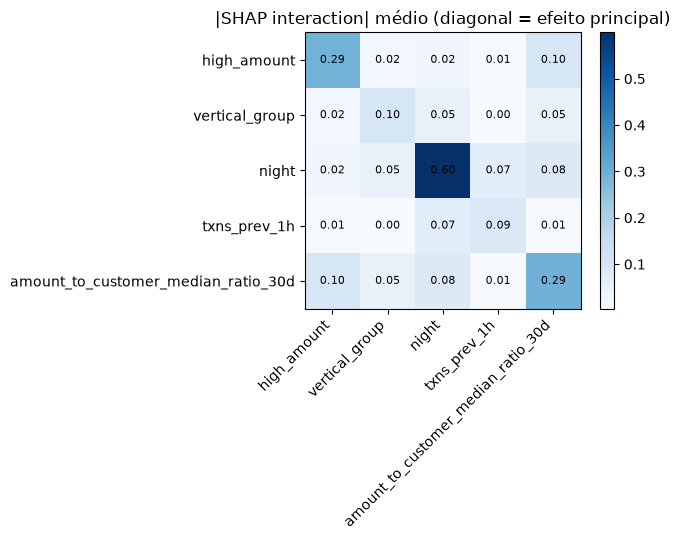

Participação das interações no |SHAP| total: 37.4%


In [11]:
# shap_interaction_values não aceita a coluna categórica: passa os códigos (mesma codificação interna do LightGBM)
X_int = X_shap.sample(3000, random_state=42)
X_int = X_int.assign(vertical_group=X_int["vertical_group"].cat.codes.astype(float))
inter = explainer.shap_interaction_values(X_int)
if isinstance(inter, list):
    inter = inter[1]
inter_abs = pd.DataFrame(np.abs(inter).mean(0), index=lgbm_features, columns=lgbm_features)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(inter_abs, cmap="Blues")
ax.set_xticks(range(len(lgbm_features)), lgbm_features, rotation=45, ha="right")
ax.set_yticks(range(len(lgbm_features)), lgbm_features)
for i in range(len(lgbm_features)):
    for j in range(len(lgbm_features)):
        ax.text(j, i, f"{inter_abs.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("|SHAP interaction| médio (diagonal = efeito principal)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

main = np.trace(inter_abs.values)
print(f"Participação das interações no |SHAP| total: {1 - main / inter_abs.values.sum():.1%}")

### Explicações locais

Três casos do teste: a fraude de maior score (verdadeiro positivo), a legítima de maior score (falso positivo) e a fraude de menor score (falso negativo). É o tipo de explicação que pode acompanhar uma transação na fila de análise manual.

TP — fraude com maior score: score 0.964, amount R$ 1,008.38


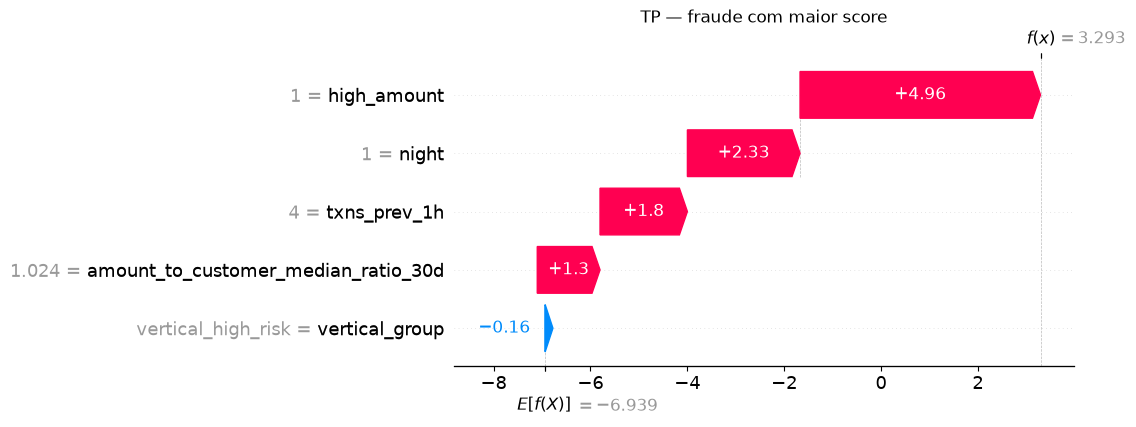

FP — legítima com maior score: score 0.932, amount R$ 534.40


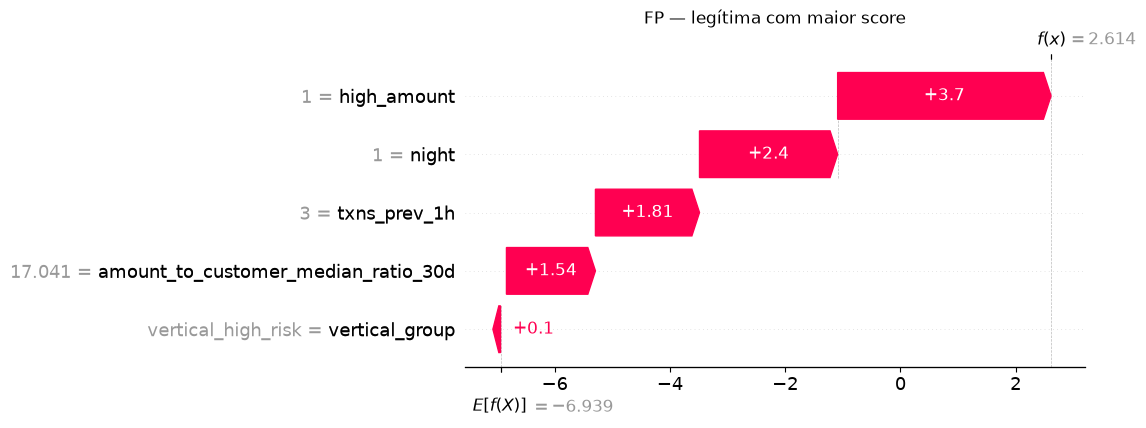

FN — fraude com menor score: score 0.000, amount R$ 52.12


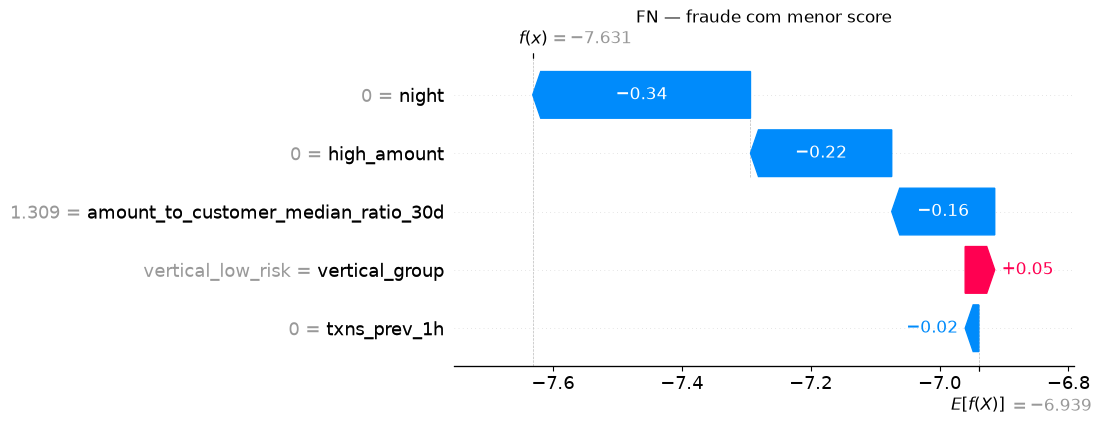

In [12]:
s_test = pd.Series(scores["test"], index=test.index)
cases = {
    "TP — fraude com maior score": s_test[y_test == 1].idxmax(),
    "FP — legítima com maior score": s_test[y_test == 0].idxmax(),
    "FN — fraude com menor score": s_test[y_test == 1].idxmin(),
}
for title, i in cases.items():
    e = explainer(X_test.loc[[i]])
    if e.values.ndim == 3:
        e = e[:, :, 1]
    print(f"{title}: score {s_test[i]:.3f}, amount R$ {test.at[i, 'amount']:,.2f}")
    shap.plots.waterfall(e[0], show=False)
    plt.title(title)
    plt.show()

## 2.3 PDP / ICE

Complementa o SHAP com a visão "o que acontece com o score se eu mudar só esta variável": PDP (média) e ICE (curvas individuais) na escala de probabilidade. ICE divergentes indicam interação.

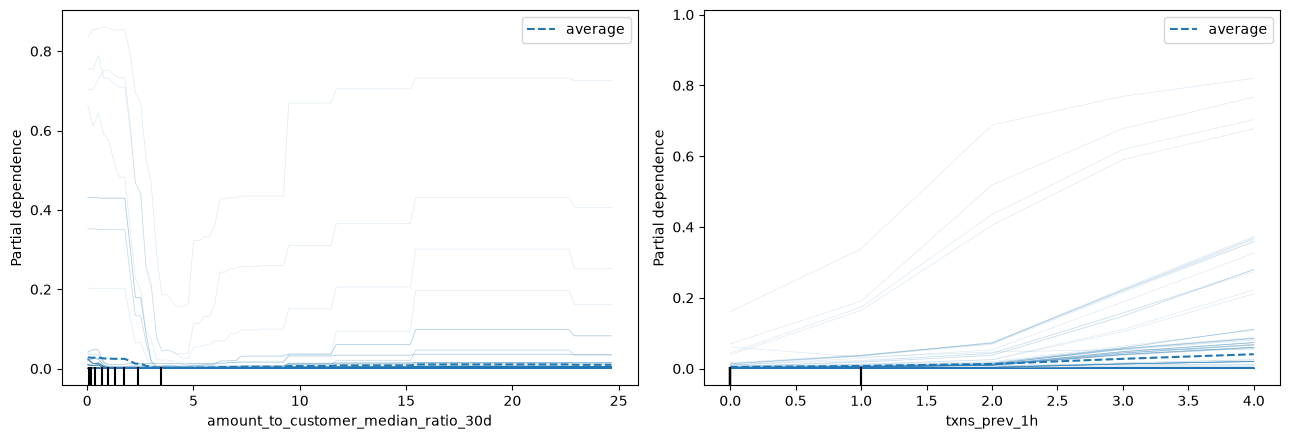

In [13]:
X_pdp = X_test.sample(2000, random_state=42).astype({"txns_prev_1h": float})  # PDP exige float
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
PartialDependenceDisplay.from_estimator(
    lgbm, X_pdp, [ratio_col], kind="both", subsample=200, random_state=42, ax=axes[0],
    ice_lines_kw={"alpha": 0.15}, percentiles=(0.01, 0.995),
)
PartialDependenceDisplay.from_estimator(
    lgbm, X_pdp, ["txns_prev_1h"], kind="both", subsample=200, random_state=42, ax=axes[1],
    ice_lines_kw={"alpha": 0.15},
)
plt.tight_layout()
plt.show()

### Sobre o LIME

Não foi usado: com apenas 5 variáveis e um modelo de árvores, o SHAP via `TreeExplainer` é **exato**, consistente e aditivo, enquanto o LIME depende de amostragem aleatória em torno do ponto e de um kernel arbitrário — as explicações variam entre execuções e são pouco confiáveis para variáveis binárias e de contagem como `night`, `high_amount` e `txns_prev_1h`. Os waterfalls acima cumprem o mesmo papel de explicação local.

# 3. Calibração

A decisão de bloqueio usa um threshold escolhido pelo custo, então a **ordenação** é o que importa para ela. Mas se o score for usado como probabilidade (perda esperada = score × amount, priorização da fila, comunicação de risco), ele precisa estar calibrado. Avaliamos:

* **curva de confiabilidade** por quantis de score (bins de igual tamanho, já que quase todo score está perto de zero);
* **Brier score** e **log loss**;
* **ECE** (erro de calibração esperado) e a razão **score médio / taxa observada**.

In [14]:
def calibration_summary(y, s, n_bins: int = 10) -> dict[str, float]:
    y, s = np.asarray(y), np.asarray(s)
    bins = pd.qcut(s, n_bins, duplicates="drop", labels=False)
    g = pd.DataFrame({"y": y, "s": s, "b": bins}).groupby("b")
    ece = (g.size() / len(y) * (g["s"].mean() - g["y"].mean()).abs()).sum()
    return {
        "fraud_rate": y.mean(),
        "mean_score": s.mean(),
        "score/taxa": s.mean() / y.mean(),
        "brier": brier_score_loss(y, s),
        "brier_ref (taxa constante)": brier_score_loss(y, np.full_like(s, y.mean(), dtype=float)),
        "log_loss": log_loss(y, s),
        "ece": ece,
    }


pd.DataFrame({name: calibration_summary(data[target], scores[name]) for name, data in splits.items()}).T

,fraud_rate,mean_score,score/taxa,brier,brier_ref (taxa constante),log_loss,ece
train,0.005683,0.005692,1.001582,0.003547,0.005651,0.015461,0.000874
valid,0.004217,0.005185,1.229380,0.002927,0.004200,0.013204,0.000967
test,0.003317,0.005056,1.524546,0.002533,0.003306,0.012114,0.001776


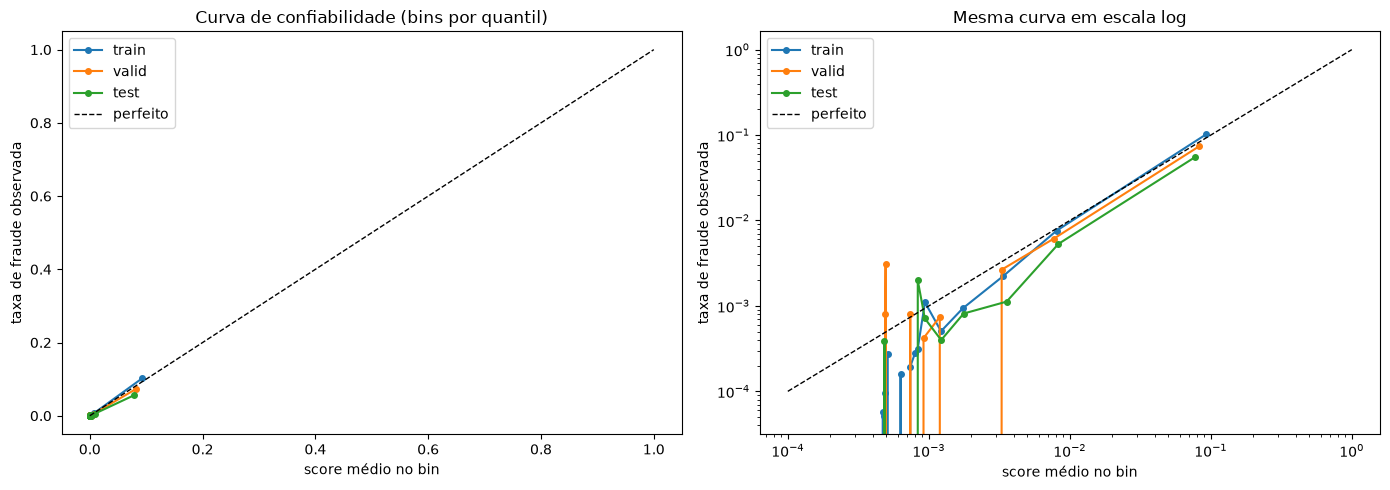

In [15]:
def reliability_plot(ax, y, s, label, n_bins=20):
    frac_pos, mean_pred = calibration_curve(y, s, n_bins=n_bins, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", ms=4, label=label)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, data in splits.items():
    for ax in axes:
        reliability_plot(ax, data[target], scores[name], name)
for ax, scale in zip(axes, ["linear", "log"]):
    lims = [1e-4, 1] if scale == "log" else [0, 1]
    ax.plot(lims, lims, "k--", lw=1, label="perfeito")
    ax.set_xscale(scale)
    ax.set_yscale(scale)
    ax.set_xlabel("score médio no bin")
    ax.set_ylabel("taxa de fraude observada")
    ax.legend()
axes[0].set_title("Curva de confiabilidade (bins por quantil)")
axes[1].set_title("Mesma curva em escala log")
plt.tight_layout()
plt.show()

### Calibração na cauda (onde a decisão acontece)

Bins por quantil concentram a curva perto de zero. Abaixo, a calibração por faixas fixas de score no teste, incluindo a faixa do threshold de decisão.

In [16]:
edges = [0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
tail = (
    pd.DataFrame({"y": y_test.to_numpy(), "s": scores["test"]})
    .assign(faixa=lambda d: pd.cut(d["s"], edges, include_lowest=True))
    .groupby("faixa", observed=True)
    .agg(n=("y", "size"), fraudes=("y", "sum"), score_medio=("s", "mean"), taxa_obs=("y", "mean"))
)
tail["obs/score"] = tail["taxa_obs"] / tail["score_medio"]
tail

,n,fraudes,score_medio,taxa_obs,obs/score
faixa,,,,,
"(-0.001, 0.001]",38416,8,0.000590,0.000208,0.352761
"(0.001, 0.005]",7824,7,0.002033,0.000895,0.440128
"(0.005, 0.01]",2155,7,0.006807,0.003248,0.477199
"(0.01, 0.02]",1469,15,0.014482,0.010211,0.705062
"(0.02, 0.05]",1019,22,0.032563,0.021590,0.663011
"(0.05, 0.1]",295,19,0.075303,0.064407,0.855296
"(0.1, 0.2]",134,10,0.155575,0.074627,0.479685
"(0.2, 0.5]",179,38,0.332695,0.212291,0.638093
"(0.5, 1.0]",66,45,0.763258,0.681818,0.893300


### Recalibração

Duas recalibrações ajustadas **na validação** e avaliadas no teste:

* **Platt** — regressão logística sobre o logit do score (2 parâmetros, corrige viés e inclinação);
* **isotônica** — monotônica não paramétrica (mais flexível, risco de overfit com poucas fraudes).

Ambas são monotônicas, então não alteram PR AUC/ROC AUC/KS (a isotônica pode criar empates); o threshold de custo é reotimizado na validação na nova escala.

In [17]:
def to_logit(s):
    s = np.clip(s, 1e-7, 1 - 1e-7)
    return np.log(s / (1 - s)).reshape(-1, 1)


platt = LogisticRegression(C=1e6).fit(to_logit(scores["valid"]), valid[target])
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(scores["valid"], valid[target])

calibrated = {
    "original": scores,
    "platt": {n: platt.predict_proba(to_logit(s))[:, 1] for n, s in scores.items()},
    "isotônica": {n: iso.predict(s) for n, s in scores.items()},
}
print(f"Platt: logit_cal = {platt.intercept_[0]:.3f} + {platt.coef_[0, 0]:.3f} × logit_score")

rows = {}
for method, sc in calibrated.items():
    thr = optimal_threshold(threshold_cost_curve(valid[target], sc["valid"], valid["amount"], **pnl_params))
    m = evaluate(y_test, sc["test"], test["amount"], thr)
    rows[method] = {
        **calibration_summary(y_test, sc["test"]),
        "pr_auc": m["pr_auc"], "threshold": thr, "block_rate": m["block_rate"], "total_cost": m["total_cost"],
    }
pd.DataFrame(rows).T

Platt: logit_cal = -0.040 + 1.090 × logit_score


,fraud_rate,mean_score,score/taxa,brier,brier_ref (taxa constante),log_loss,ece,pr_auc,threshold,block_rate,total_cost
original,0.003317,0.005056,1.524546,0.002533,0.003306,0.012114,0.001776,0.400001,0.113381,0.007138,41364.477
platt,0.003317,0.004045,1.219529,0.002504,0.003306,0.011763,0.000875,0.400001,0.092522,0.007138,41364.477
isotônica,0.003317,0.004040,1.217924,0.002493,0.003306,0.012837,0.000860,0.359460,0.169492,0.007138,41364.477


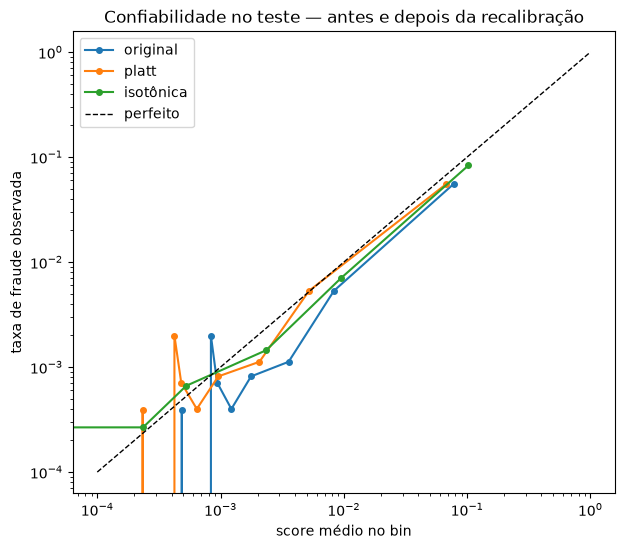

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
for method, sc in calibrated.items():
    reliability_plot(ax, y_test, sc["test"], method)
ax.plot([1e-4, 1], [1e-4, 1], "k--", lw=1, label="perfeito")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("score médio no bin")
ax.set_ylabel("taxa de fraude observada")
ax.set_title("Confiabilidade no teste — antes e depois da recalibração")
ax.legend()
plt.show()

# Conclusões

In [19]:
t = metrics.loc["test"]
cal_test = calibration_summary(y_test, scores["test"])
top_perm = importances.index[0]
print(f"""Reprodução: PR AUC {t.pr_auc:.3f}, ROC AUC {t.roc_auc:.3f}, KS {t.ks:.3f}, custo R$ {t.total_cost:,.0f}
  no teste (threshold {threshold:.3f}, bloqueio {t.block_rate:.2%}) — diferença máx. vs notebook 3:
  {check['diferença'].abs().max():.2e}.

Explicabilidade: a variável mais importante por permutação no teste é `{top_perm}`.
  Ordem por queda de PR AUC: {', '.join(importances.index)}.
  Interações respondem por {1 - main / inter_abs.values.sum():.0%} do |SHAP| total.

Calibração (teste): score médio {cal_test['mean_score']:.4f} vs taxa observada {cal_test['fraud_rate']:.4f}
  (razão {cal_test['score/taxa']:.2f}); ECE {cal_test['ece']:.4f}; Brier {cal_test['brier']:.5f}
  vs {cal_test['brier_ref (taxa constante)']:.5f} de um score constante.
""")

Reprodução: PR AUC 0.400, ROC AUC 0.962, KS 0.824, custo R$ 41,364
  no teste (threshold 0.113, bloqueio 0.71%) — diferença máx. vs notebook 3:
  3.85e-07.

Explicabilidade: a variável mais importante por permutação no teste é `high_amount`.
  Ordem por queda de PR AUC: high_amount, night, amount_to_customer_median_ratio_30d, txns_prev_1h, vertical_group.
  Interações respondem por 37% do |SHAP| total.

Calibração (teste): score médio 0.0051 vs taxa observada 0.0033
  (razão 1.52); ECE 0.0018; Brier 0.00253
  vs 0.00331 de um score constante.



**Leitura**:

* **Reprodução**: as métricas de escolha do notebook 3 batem (diferenças < 1e-6; custo idêntico, R$ 41.364 no teste). O threshold da validação (0,113) deixa ~R$ 2,9 mil na mesa frente ao ótimo *ex post* do teste (0,196) — custo razoável de não olhar o futuro.
* **Importância**: `high_amount` e `night` lideram em PR AUC. Pelo custo, a razão sobre a mediana de 30d empata com `high_amount` (~R$ 61–63 mil de piora se embaralhada): é ela que separa as fraudes de valor alto, que pesam no P&L. `txns_prev_1h` e `vertical_group` ajudam a ordenação, mas quase não mexem no custo no threshold escolhido.
* **SHAP**: aditividade exata (erro ~1e-14). A dependência mostra o degrau da razão no último decil e o efeito crescente da velocidade — não linear. As interações respondem por ~37% do |SHAP| total: o modelo não é aditivo no logit, o que explica o salto sobre a regressão logística (PR AUC 0,21 → 0,40).
* **Calibração**: perfeita no treino (score/taxa = 1,00), mas **superestima** em validação (1,23) e teste (1,52), em todas as faixas de score. É deriva da taxa de fraude (0,57% → 0,33%), não defeito de ordenação. O Brier fica bem abaixo do score constante.
* **Recalibração**: Platt (ajustado na validação) reduz o ECE pela metade, mantém PR AUC e o custo é idêntico (transformação monotônica → mesmo conjunto bloqueado). A isotônica calibra igual, mas cria empates e perde PR AUC (0,40 → 0,36). Para a decisão de bloqueio a calibração é irrelevante; se o score for usado como probabilidade (perda esperada, fila), usar Platt numa janela recente, recalibrar periodicamente e monitorar a razão score/taxa em produção.